In [1]:
import sys
import importlib.util
from pathlib import Path

import pandas as pd

def find_project_root(start_path=None):
    if start_path is None:
        start_path = Path.cwd()
    else:
        start_path = Path(start_path)

    current = start_path.resolve()

    while True:
        if (current / "09_config.py").exists() and (current / "08_utils.py").exists():
            return current
        if current.parent == current:
            raise FileNotFoundError("Project root tidak ditemukan.")
        current = current.parent

def import_py_file(module_name, file_path):
    file_path = Path(file_path).resolve()
    spec = importlib.util.spec_from_file_location(module_name, file_path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)
    return module

PROJECT_ROOT = find_project_root()
cfg = import_py_file("ferplus_config", PROJECT_ROOT / "09_config.py")
utils = import_py_file("ferplus_utils", PROJECT_ROOT / "08_utils.py")

utils.set_global_seed(cfg.SEED)
utils.ensure_directories()

print("Evaluasi final menggunakan test set yang sama:")
print(cfg.TEST_DIR)

TensorFlow op determinism: ENABLED
Evaluasi final menggunakan test set yang sama:
C:\Users\Davin\Downloads\Skripsi\project_skripsi\dataset\test


In [2]:
for model_label, model_path in cfg.MODEL_PATHS.items():
    model_path = Path(model_path)

    print(model_label)
    print("Path:", model_path)
    print("Exists:", model_path.exists())
    print("Size MB:", utils.get_model_file_size_mb(model_path))
    print("-" * 80)

Model 1 - Baseline No Augmentation
Path: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_1_baseline_no_augmentation_best.keras
Exists: True
Size MB: 16.372572898864746
--------------------------------------------------------------------------------
Model 2 - Training Full + Augmentation
Path: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_2_training_full_with_augmentation_best.keras
Exists: True
Size MB: 16.38714027404785
--------------------------------------------------------------------------------
Model 3 - Training Full + Augmentation + Fine Tuning
Path: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_3_training_full_augmentation_finetuning_best.keras
Exists: True
Size MB: 35.534677505493164
--------------------------------------------------------------------------------


In [3]:
test_ds, test_file_paths = utils.load_common_test_dataset(return_file_paths=True)

print("Jumlah file test berdasarkan file_paths:", len(test_file_paths))

y_true_check = utils.get_true_labels(test_ds)
print("Jumlah label test terbaca:", len(y_true_check))

if len(test_file_paths) != len(y_true_check):
    print("PERINGATAN: Jumlah file path dan label tidak sama.")
else:
    print("AMAN: Jumlah file path dan label sama.")

Found 3573 files belonging to 8 classes.
Jumlah file test berdasarkan file_paths: 3573
Jumlah label test terbaca: 3573
AMAN: Jumlah file path dan label sama.


In [4]:
summary_rows = []
report_dicts = {}
report_texts = {}
confusion_matrices = {}
prediction_dfs = {}

for model_label, model_path in cfg.MODEL_PATHS.items():
    summary, report_dict, report_text, cm, pred_df, y_true, y_pred, y_prob = utils.evaluate_saved_model_on_test(
        model_label=model_label,
        model_path=model_path,
        test_ds=test_ds,
        test_file_paths=test_file_paths
    )

    if model_label.startswith("Model 1"):
        time_file = cfg.LOG_DIR / "model_1_baseline_no_augmentation_training_time.json"

        if time_file.exists():
            time_info = utils.load_json(time_file)
            training_time_seconds = time_info.get("duration_seconds", 0)
        else:
            print(f"File training time tidak ditemukan: {time_file}")
            training_time_seconds = 0

    elif model_label.startswith("Model 2"):
        time_file = cfg.LOG_DIR / "model_2_training_full_with_augmentation_training_time.json"

        if time_file.exists():
            time_info = utils.load_json(time_file)
            training_time_seconds = time_info.get("duration_seconds", 0)
        else:
            print(f"File training time tidak ditemukan: {time_file}")
            training_time_seconds = 0

    elif model_label.startswith("Model 3"):
        time_file = cfg.LOG_DIR / "model_3_training_full_augmentation_finetuning_training_time.json"

        if time_file.exists():
            time_info = utils.load_json(time_file)
            training_time_seconds = time_info.get("total_duration_seconds", 0)
        else:
            print(f"File training time tidak ditemukan: {time_file}")
            training_time_seconds = 0

    else:
        training_time_seconds = 0

    summary["training_time_seconds"] = training_time_seconds
    summary["training_time_formatted"] = utils.format_seconds(training_time_seconds)

    summary_rows.append(summary)
    report_dicts[model_label] = report_dict
    report_texts[model_label] = report_text
    confusion_matrices[model_label] = cm
    prediction_dfs[model_label] = pred_df

comparison_df = pd.DataFrame(summary_rows)
results_with_training_time_df = comparison_df.copy()

display_columns = [
    "model",
    "test_loss",
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "precision_weighted",
    "recall_weighted",
    "f1_weighted",
    "training_time_formatted",
    "model_size_mb"
]

display_df = results_with_training_time_df[display_columns].copy()

percentage_columns = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "precision_weighted",
    "recall_weighted",
    "f1_weighted"
]

for column in percentage_columns:
    display_df[column] = display_df[column] * 100

display_df = display_df.round({
    "test_loss": 4,
    "accuracy": 2,
    "precision_macro": 2,
    "recall_macro": 2,
    "f1_macro": 2,
    "precision_weighted": 2,
    "recall_weighted": 2,
    "f1_weighted": 2,
    "model_size_mb": 2
})

display(display_df)


EVALUASI: Model 1 - Baseline No Augmentation
Model path: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_1_baseline_no_augmentation_best.keras
112/112 ━━━━━━━━━━━━━━━━━━━━ 34s 279ms/step - accuracy: 0.5781 - loss: 1.2057
112/112 ━━━━━━━━━━━━━━━━━━━━ 36s 315ms/step

EVALUASI: Model 2 - Training Full + Augmentation
Model path: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_2_training_full_with_augmentation_best.keras
112/112 ━━━━━━━━━━━━━━━━━━━━ 38s 321ms/step - accuracy: 0.5832 - loss: 1.1913
112/112 ━━━━━━━━━━━━━━━━━━━━ 39s 333ms/step

EVALUASI: Model 3 - Training Full + Augmentation + Fine Tuning
Model path: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\models\model_3_training_full_augmentation_finetuning_best.keras
112/112 ━━━━━━━━━━━━━━━━━━━━ 34s 288ms/step - accuracy: 0.7767 - loss: 0.7570
112/112 ━━━━━━━━━━━━━━━━━━━━ 33s 280ms/step


,model,test_loss,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,training_time_formatted,model_size_mb
0,Model 1 - Baseline No Augmentation,0.9696,66.13,56.22,40.71,43.02,65.06,66.13,64.11,01:11:58.94,16.37
1,Model 2 - Training Full + Augmentation,1.0502,64.04,49.14,45.22,45.08,64.70,64.04,63.78,02:30:49.02,16.39
2,Model 3 - Training Full + Augmentation + Fine ...,0.6637,78.84,64.55,64.82,64.13,78.66,78.84,78.68,08:50:16.25,35.53


In [5]:
comparison_df["composite_score"] = comparison_df[
    [
        "accuracy",
        "f1_macro",
        "f1_weighted",
        "recall_macro"
    ]
].mean(axis=1)

comparison_df = comparison_df.sort_values(
    by=["composite_score", "f1_macro", "accuracy"],
    ascending=False
).reset_index(drop=True)

display(comparison_df)

best_model_row = comparison_df.iloc[0]

print("Model terbaik berdasarkan composite score:")
print("Model:", best_model_row["model"])
print("Composite score:", best_model_row["composite_score"])
print("Accuracy:", best_model_row["accuracy"])
print("Macro F1:", best_model_row["f1_macro"])
print("Weighted F1:", best_model_row["f1_weighted"])
print("Macro Recall:", best_model_row["recall_macro"])

,model,test_loss,test_accuracy_from_evaluate,accuracy,precision_micro,recall_micro,f1_micro,precision_macro,recall_macro,f1_macro,...,f1_weighted,num_test_images,evaluation_time_seconds,inference_time_seconds,avg_inference_time_per_image_ms,model_size_mb,model_path,training_time_seconds,training_time_formatted,composite_score
0,Model 3 - Training Full + Augmentation + Fine ...,0.663733,0.788413,0.788413,0.788413,0.788413,0.788413,0.645451,0.648218,0.641261,...,0.786835,3573,34.409881,32.732023,9.160935,35.534678,C:\Users\Davin\Downloads\Skripsi\project_skrip...,31816.253192,08:50:16.25,0.716182
1,Model 2 - Training Full + Augmentation,1.050157,0.640358,0.640358,0.640358,0.640358,0.640358,0.491353,0.452221,0.450771,...,0.637846,3573,38.043611,38.572910,10.795665,16.387140,C:\Users\Davin\Downloads\Skripsi\project_skrip...,9049.016472,02:30:49.02,0.545299
2,Model 1 - Baseline No Augmentation,0.969615,0.661349,0.661349,0.661349,0.661349,0.661349,0.562246,0.407055,0.430194,...,0.641099,3573,33.536843,36.430087,10.195938,16.372573,C:\Users\Davin\Downloads\Skripsi\project_skrip...,4318.943599,01:11:58.94,0.534924


Model terbaik berdasarkan composite score:
Model: Model 3 - Training Full + Augmentation + Fine Tuning
Composite score: 0.7161818136210227
Accuracy: 0.7884130982367759
Macro F1: 0.6412613973361219
Weighted F1: 0.7868350516159891
Macro Recall: 0.6482177072952042


In [6]:
comparison_path = cfg.RESULT_DIR / "comparison_results_3_models.csv"
comparison_df.to_csv(comparison_path, index=False)

print("Tabel perbandingan disimpan ke:", comparison_path)

Tabel perbandingan disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\comparison_results_3_models.csv


In [7]:
for model_label, report_dict in report_dicts.items():
    safe_name = (
        model_label
        .lower()
        .replace(" ", "_")
        .replace("-", "")
        .replace("+", "plus")
    )

    report_df = pd.DataFrame(report_dict).transpose()

    report_path = cfg.RESULT_DIR / f"classification_report_{safe_name}.csv"
    report_df.to_csv(report_path)

    print("\n" + "=" * 80)
    print(model_label)
    print("=" * 80)
    print(report_texts[model_label])
    print("Classification report disimpan ke:", report_path)


Model 1 - Baseline No Augmentation
              precision    recall  f1-score   support

       angry       0.66      0.32      0.43       322
    contempt       0.67      0.07      0.12        30
     disgust       0.00      0.00      0.00        21
        fear       0.60      0.18      0.28        98
       happy       0.70      0.78      0.74       929
     neutral       0.66      0.80      0.72      1274
         sad       0.53      0.38      0.44       449
    surprise       0.69      0.72      0.70       450

    accuracy                           0.66      3573
   macro avg       0.56      0.41      0.43      3573
weighted avg       0.65      0.66      0.64      3573

Classification report disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\classification_report_model_1__baseline_no_augmentation.csv

Model 2 - Training Full + Augmentation
              precision    recall  f1-score   support

       angry       0.57      0.39      0.46       322
    

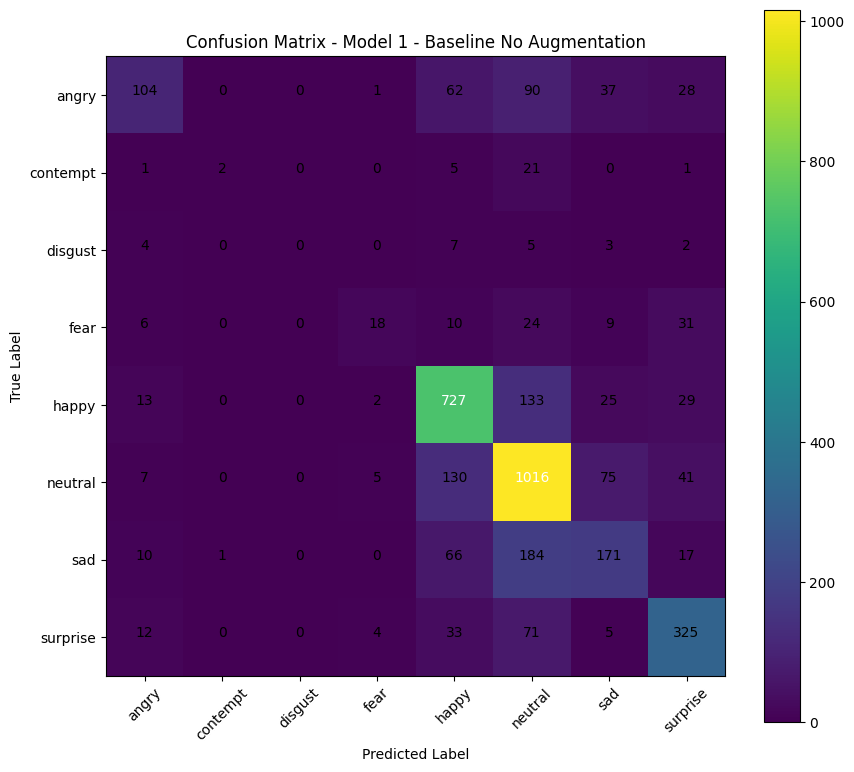

Confusion matrix disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\confusion_matrix_model_1__baseline_no_augmentation.png


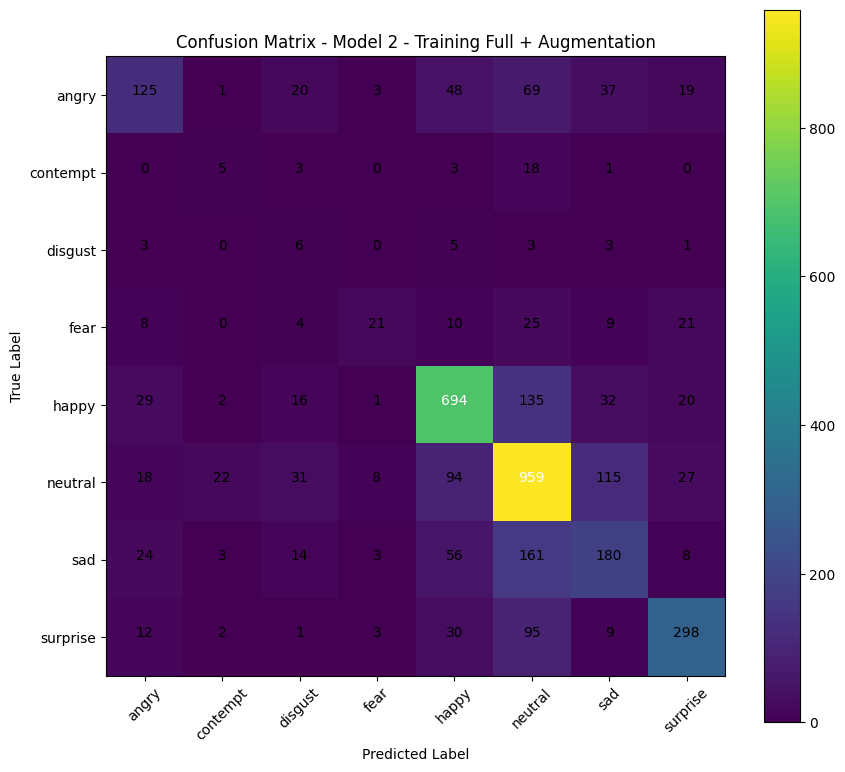

Confusion matrix disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\confusion_matrix_model_2__training_full_plus_augmentation.png


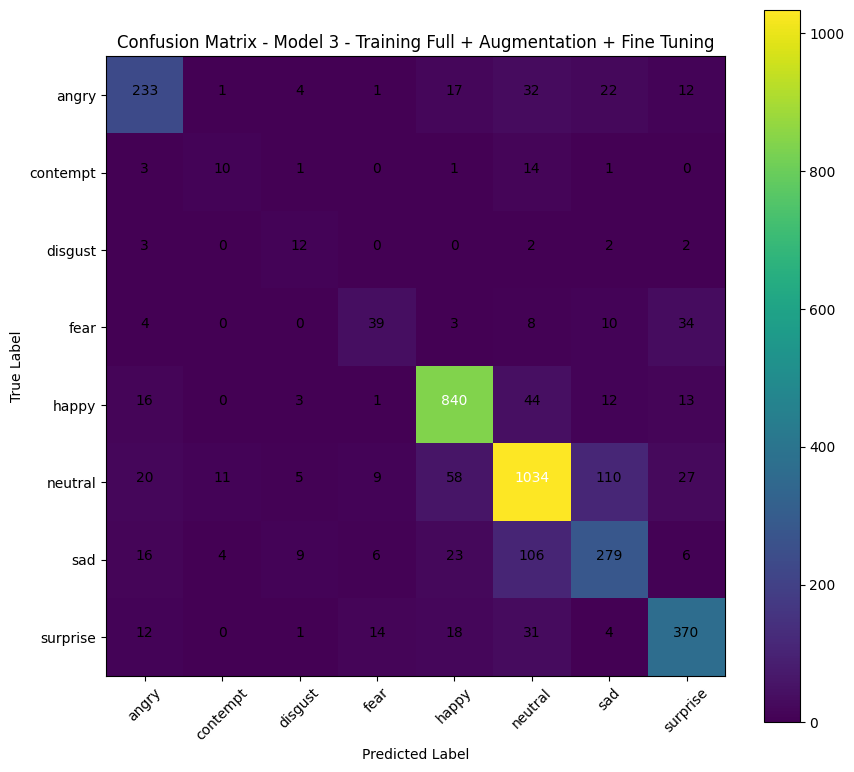

Confusion matrix disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\confusion_matrix_model_3__training_full_plus_augmentation_plus_fine_tuning.png


In [8]:
for model_label, cm in confusion_matrices.items():
    safe_name = (
        model_label
        .lower()
        .replace(" ", "_")
        .replace("-", "")
        .replace("+", "plus")
    )

    cm_path = cfg.FIGURE_DIR / f"confusion_matrix_{safe_name}.png"

    utils.plot_confusion_matrix(
        cm=cm,
        title=f"Confusion Matrix - {model_label}",
        save_path=cm_path
    )

    print("Confusion matrix disimpan ke:", cm_path)

In [9]:
for model_label, pred_df in prediction_dfs.items():
    safe_name = (
        model_label
        .lower()
        .replace(" ", "_")
        .replace("-", "")
        .replace("+", "plus")
    )

    pred_path = cfg.RESULT_DIR / f"test_predictions_{safe_name}.csv"
    pred_df.to_csv(pred_path, index=False)

    print("Prediksi test disimpan ke:", pred_path)

Prediksi test disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\test_predictions_model_1__baseline_no_augmentation.csv
Prediksi test disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\test_predictions_model_2__training_full_plus_augmentation.csv
Prediksi test disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\results\test_predictions_model_3__training_full_plus_augmentation_plus_fine_tuning.csv


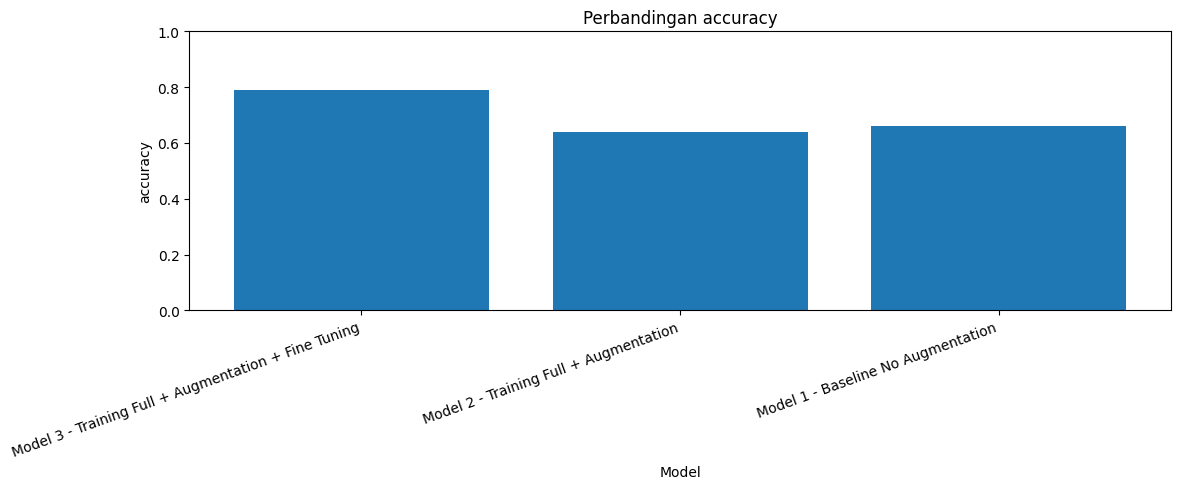

Grafik disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\comparison_accuracy.png


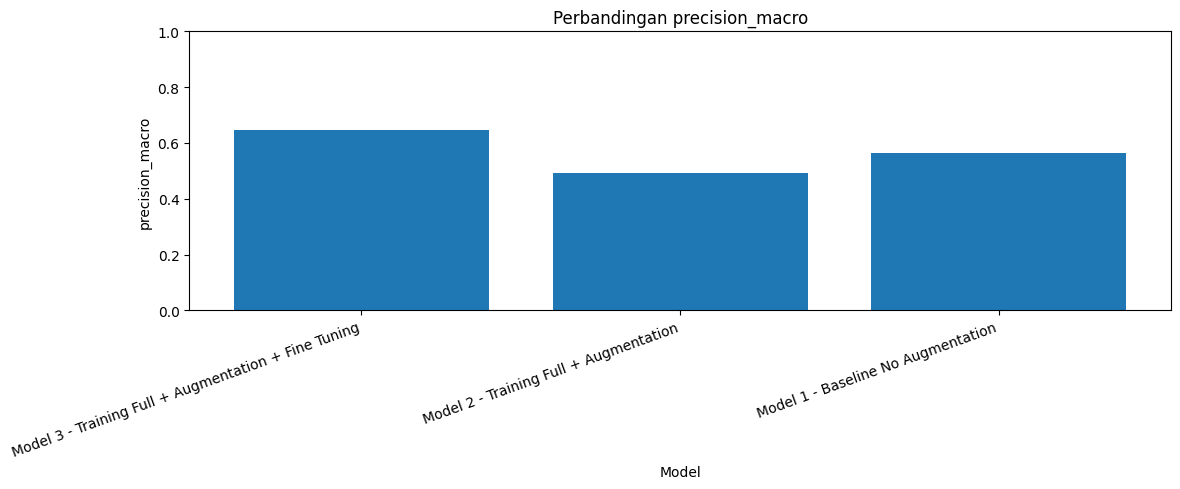

Grafik disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\comparison_precision_macro.png


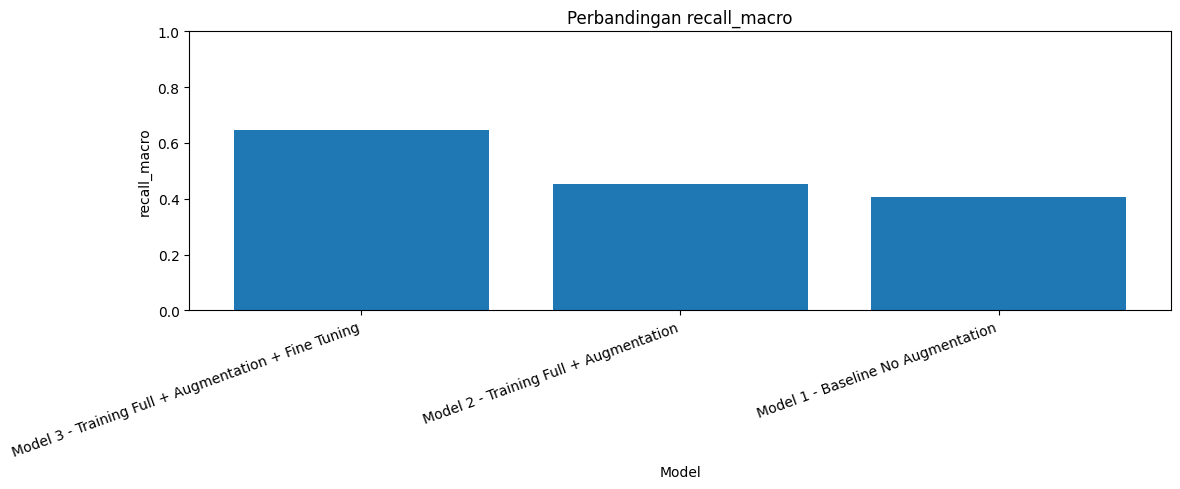

Grafik disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\comparison_recall_macro.png


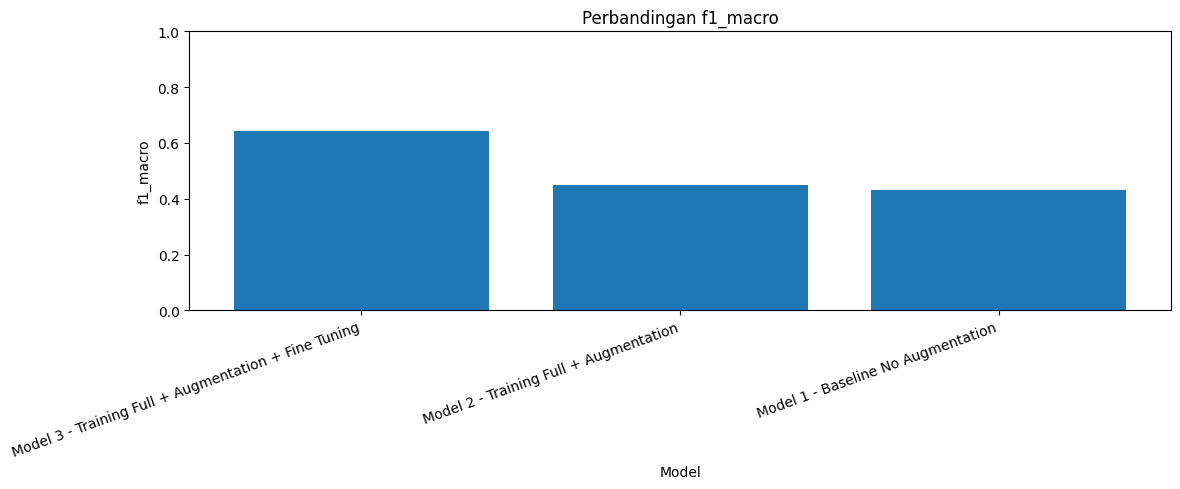

Grafik disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\comparison_f1_macro.png


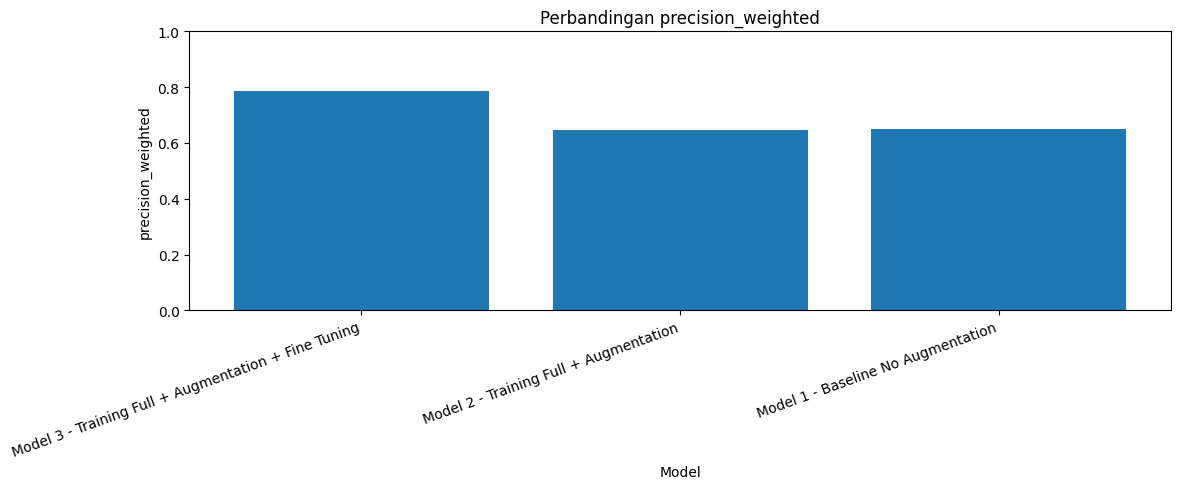

Grafik disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\comparison_precision_weighted.png


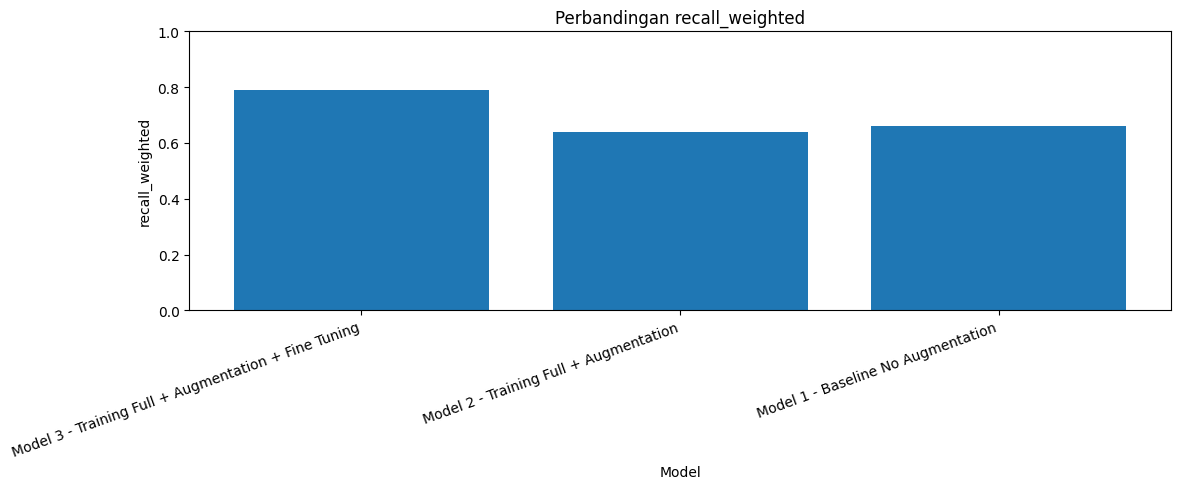

Grafik disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\comparison_recall_weighted.png


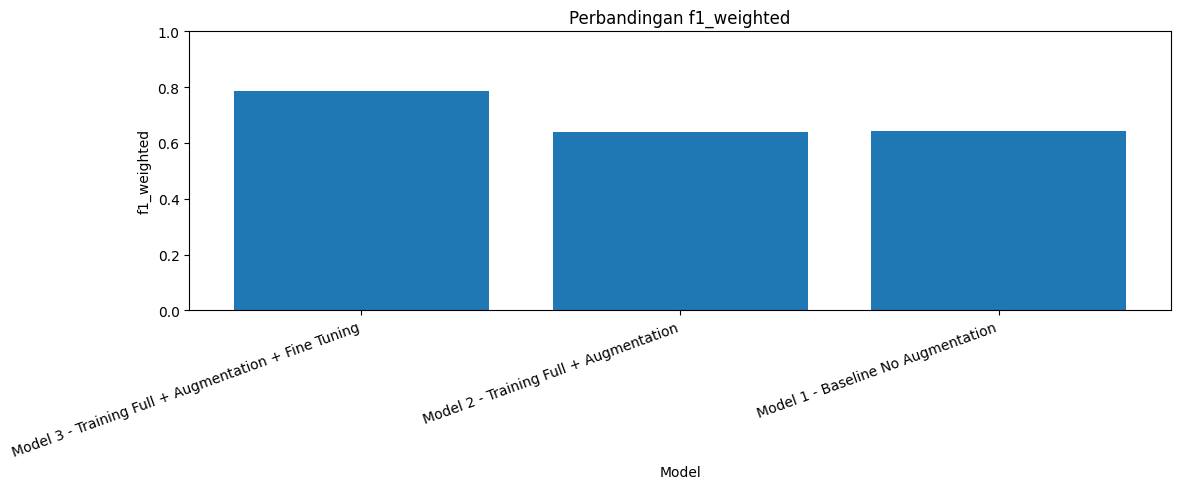

Grafik disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\comparison_f1_weighted.png


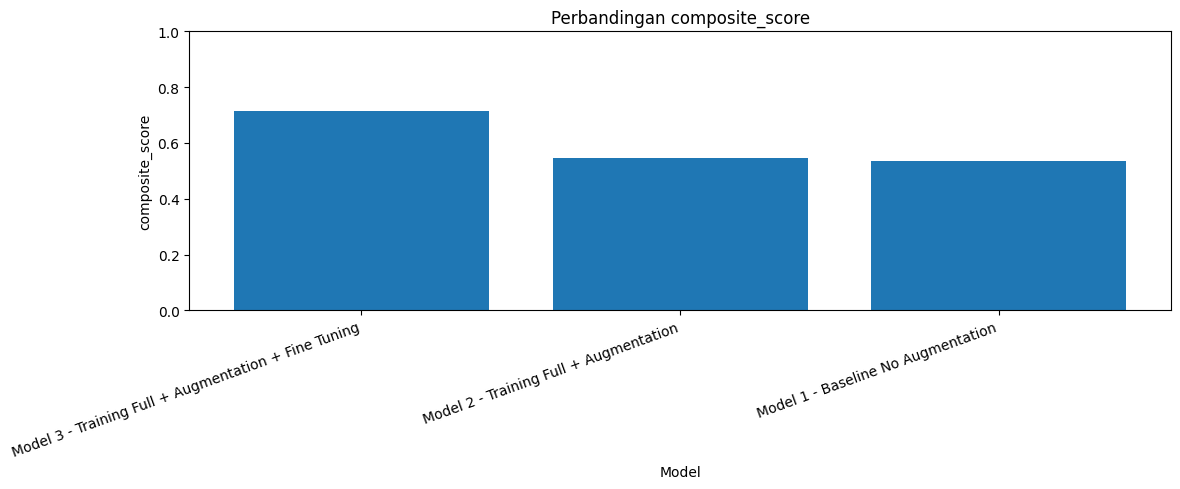

Grafik disimpan ke: C:\Users\Davin\Downloads\Skripsi\project_skripsi\outputs\figures\comparison_composite_score.png


In [10]:
import matplotlib.pyplot as plt

metrics = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "precision_weighted",
    "recall_weighted",
    "f1_weighted",
    "composite_score"
]

for metric in metrics:
    plt.figure(figsize=(12, 5))

    plt.bar(comparison_df["model"], comparison_df[metric])

    plt.title(f"Perbandingan {metric}")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()

    save_path = cfg.FIGURE_DIR / f"comparison_{metric}.png"
    plt.savefig(save_path, dpi=300)
    plt.show()

    print("Grafik disimpan ke:", save_path)